In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

train = pd.read_csv(ROOT / "data" / "train.csv")
test = pd.read_csv(ROOT / "data" / "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)
display(train.head())

Train: (533465, 17)
Test: (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


In [2]:
print("Informasi data:")
train.info()

print("\nMissing values:")
display(
    train.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\nJumlah duplikasi:")
print("Duplikasi baris:", train.duplicated().sum())
print(
    "Duplikasi building_id:",
    train["building_id"].duplicated().sum()
)

print("\nJumlah kategori target:")
display(train["damage_grade"].value_counts())


Informasi data:
<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  


,missing_count
building_id,0
district_id,0
vdcmun_id,0
ward_id,0
count_floors_pre_eq,0
age_building,0
plinth_area_sq_ft,0
height_ft_pre_eq,0
land_surface_condition,0
foundation_type,0



Jumlah duplikasi:
Duplikasi baris: 0
Duplikasi building_id: 0

Jumlah kategori target:


damage_grade
Grade 5    193036
Grade 4    128691
Grade 3     95488
Grade 2     61080
Grade 1     55170
Name: count, dtype: int64

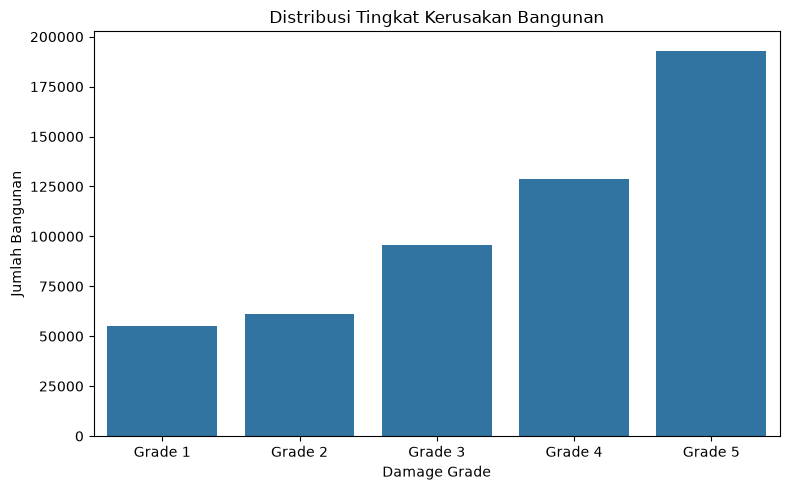

In [3]:
plt.figure(figsize=(8, 5))

order = sorted(train["damage_grade"].unique())

sns.countplot(
    data=train,
    x="damage_grade",
    order=order,
)

plt.title("Distribusi Tingkat Kerusakan Bangunan")
plt.xlabel("Damage Grade")
plt.ylabel("Jumlah Bangunan")
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


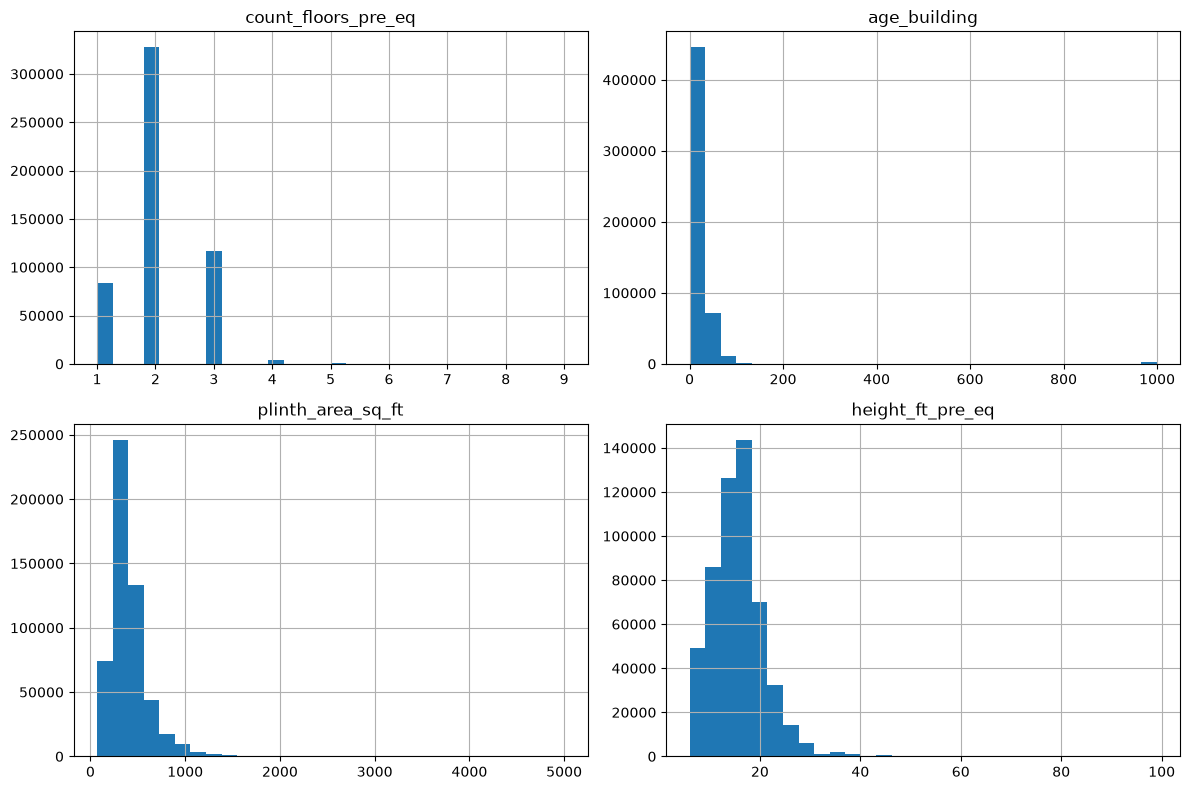

In [4]:
numeric_cols = [
    "count_floors_pre_eq",
    "age_building",
    "plinth_area_sq_ft",
    "height_ft_pre_eq",
]

display(train[numeric_cols].describe().T)

train[numeric_cols].hist(
    figsize=(12, 8),
    bins=30,
)

plt.tight_layout()
plt.show()

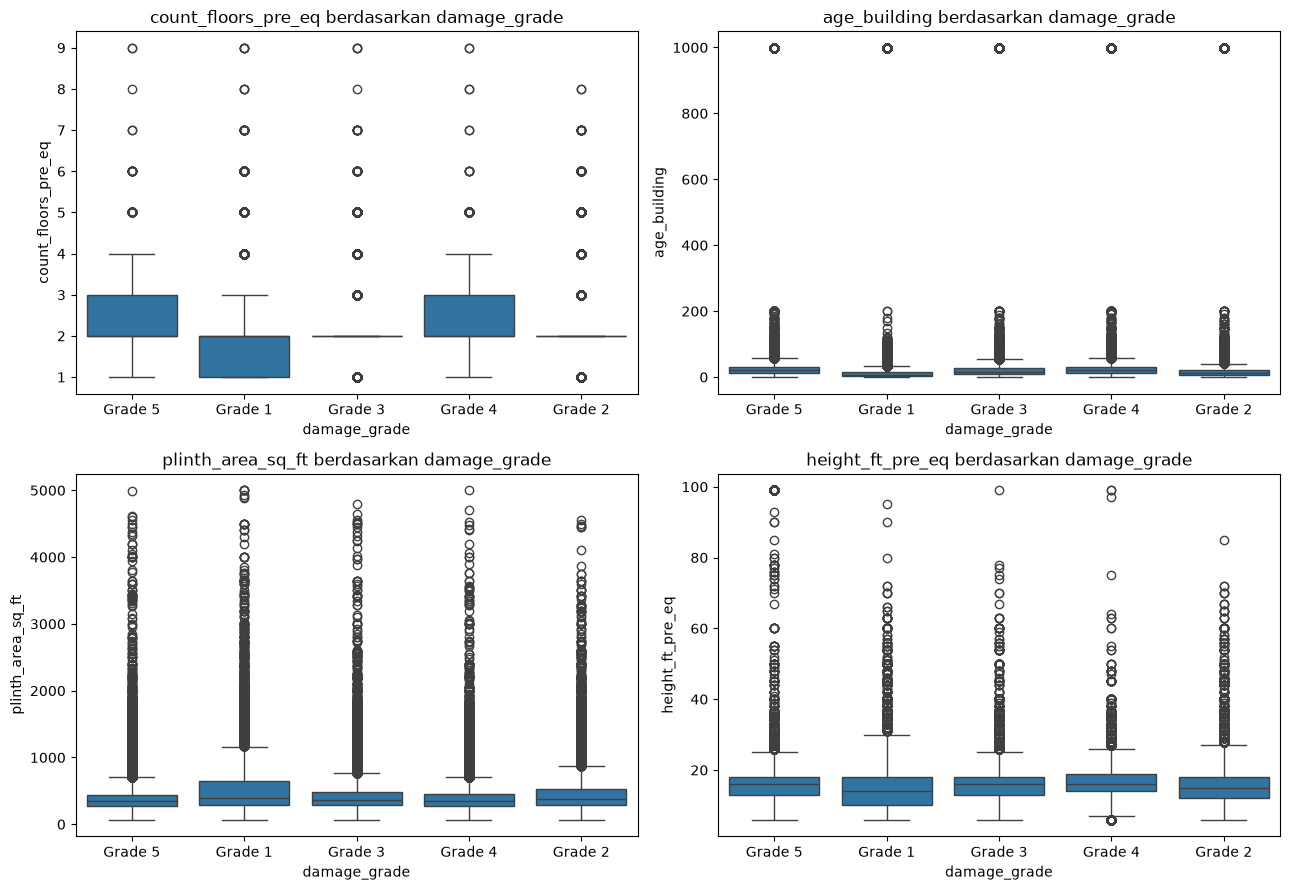

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(numeric_cols, axes.flat):
    sns.boxplot(
        data=train,
        x="damage_grade",
        y=col,
        ax=ax,
    )
    ax.set_title(f"{col} berdasarkan damage_grade")

plt.tight_layout()
plt.show()